In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# BIKES DATA FOR ANALYSIS

In [4]:
df = pd.read_csv(r'/content/raw_bike_data.csv')
df.head()

,Bike_Name,Brand,Price,Mileage,Engine_Capacity,Transmission,Kerb_Weight,Fuel_Tank_Capacity,User_Rating,Fuel_Type,URL
0,TVS Apache RTR 160,TVS,110695.0,61.0,159.70,5 Speed Manual,137.0,12.0,4.5,Petrol,https://www.bikewale.com/tvs-bikes/apache-160/
1,TVS Apache RTR 180 [2018-2019],TVS,110695.0,46.0,177.00,5 Speed Manual,139.0,16.0,4.6,Petrol,https://www.bikewale.com/tvs-bikes/apache-180-...
2,TVS Apache RTR 180,TVS,127722.0,42.0,177.40,5 Speed Manual,140.0,12.0,4.6,Petrol,https://www.bikewale.com/tvs-bikes/apache-180/
3,TVS Apache RTR 200 4V,TVS,138353.0,41.9,197.75,5 Speed Manual,152.0,12.0,4.5,Petrol,https://www.bikewale.com/tvs-bikes/apache-200/
4,TVS Apache [2006],TVS,110695.0,18.0,NaN,NaN,NaN,NaN,4.5,NaN,https://www.bikewale.com/tvs-bikes/apache-2006/


# DATA CLEANING

Data Understanding

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1032 entries, 0 to 1031
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Bike_Name           1032 non-null   object 
 1   Brand               1032 non-null   object 
 2   Price               1032 non-null   float64
 3   Mileage             958 non-null    float64
 4   Engine_Capacity     831 non-null    float64
 5   Transmission        882 non-null    object 
 6   Kerb_Weight         793 non-null    float64
 7   Fuel_Tank_Capacity  785 non-null    float64
 8   User_Rating         732 non-null    float64
 9   Fuel_Type           840 non-null    object 
 10  URL                 1032 non-null   object 
dtypes: float64(6), object(5)
memory usage: 88.8+ KB


In [6]:
df.shape

(1032, 11)

In [7]:
df.head()

,Bike_Name,Brand,Price,Mileage,Engine_Capacity,Transmission,Kerb_Weight,Fuel_Tank_Capacity,User_Rating,Fuel_Type,URL
0,TVS Apache RTR 160,TVS,110695.0,61.0,159.70,5 Speed Manual,137.0,12.0,4.5,Petrol,https://www.bikewale.com/tvs-bikes/apache-160/
1,TVS Apache RTR 180 [2018-2019],TVS,110695.0,46.0,177.00,5 Speed Manual,139.0,16.0,4.6,Petrol,https://www.bikewale.com/tvs-bikes/apache-180-...
2,TVS Apache RTR 180,TVS,127722.0,42.0,177.40,5 Speed Manual,140.0,12.0,4.6,Petrol,https://www.bikewale.com/tvs-bikes/apache-180/
3,TVS Apache RTR 200 4V,TVS,138353.0,41.9,197.75,5 Speed Manual,152.0,12.0,4.5,Petrol,https://www.bikewale.com/tvs-bikes/apache-200/
4,TVS Apache [2006],TVS,110695.0,18.0,NaN,NaN,NaN,NaN,4.5,NaN,https://www.bikewale.com/tvs-bikes/apache-2006/


In [8]:
#Random sample
df.sample(10)

,Bike_Name,Brand,Price,Mileage,Engine_Capacity,Transmission,Kerb_Weight,Fuel_Tank_Capacity,User_Rating,Fuel_Type,URL
208,Yamaha Alba,Yamaha,1295800.0,18.0,NaN,NaN,NaN,NaN,NaN,NaN,https://www.bikewale.com/yamaha-bikes/alba/
920,Ather Konarc,Ather,101209.0,NaN,NaN,Automatic,NaN,NaN,4.8,Electric,https://www.bikewale.com/ather-bikes/konarc/
1012,Ducati Scrambler Icon,Ducati,1086986.0,19.0,803.00,6 Speed Manual,185.0,13.5,NaN,Petrol,https://www.bikewale.com/ducati-bikes/scramble...
581,Suzuki GSX-S1000 [2019-2020],Suzuki,1383800.0,14.0,999.00,6 Speed Manual,209.0,17.0,NaN,Petrol,https://www.bikewale.com/suzuki-bikes/gsx-s100...
405,Bajaj V15,Bajaj,79537.0,57.0,149.50,5 Speed Manual,135.0,13.0,4.2,Petrol,https://www.bikewale.com/bajaj-bikes/v15/
835,BMW S 1000 XR,BMW,2375000.0,16.0,999.00,6 Speed Manual,227.0,20.0,4.7,Petrol,https://www.bikewale.com/bmw-bikes/s-1000-xr/
685,Kawasaki Ninja H2 [2018-2019],Kawasaki,317000.0,34.0,998.00,6 Speed Manual,238.0,17.0,4.8,Petrol,https://www.bikewale.com/kawasaki-bikes/ninja-...
259,Yamaha PW50,Yamaha,1279000.0,18.0,NaN,NaN,NaN,NaN,NaN,NaN,https://www.bikewale.com/yamaha-bikes/pw50/
89,Honda CB Shine SP,Honda,84372.0,57.0,124.73,5 Speed Manual,124.0,10.5,1.0,Petrol,https://www.bikewale.com/honda-bikes/cb-shine-sp/
303,Yamaha XS2,Yamaha,783000.0,56.0,NaN,NaN,NaN,NaN,NaN,NaN,https://www.bikewale.com/yamaha-bikes/xs2/


In [9]:
df.dtypes

,0
Bike_Name,object
Brand,object
Price,float64
Mileage,float64
Engine_Capacity,float64
Transmission,object
Kerb_Weight,float64
Fuel_Tank_Capacity,float64
User_Rating,float64
Fuel_Type,object


In [10]:
#Unique Values - Number of unique bikes
print("Unique Bike Names:", df["Bike_Name"].nunique())

Unique Bike Names: 1032


In [11]:
#Unique Values - Number of brands
print("Unique Brands:", df["Brand"].nunique())

Unique Brands: 14


In [12]:
#Brands
print(df["Brand"].unique())

['TVS' 'Honda' 'Yamaha' 'Bajaj' 'Hero' 'KTM' 'Suzuki' 'Kawasaki' 'BMW'
 'Aprilia' 'Benelli' 'Ampere' 'Ather' 'Ducati']


In [13]:
#Number of transmissions
print("Unique Transmissions:",
      df["Transmission"].nunique())

Unique Transmissions: 8


In [14]:
#Fuel types
print("Fuel Types:")
print(df["Fuel_Type"].value_counts(dropna=False))

Fuel Types:
Fuel_Type
Petrol      802
NaN         192
Electric     36
Cng           2
Name: count, dtype: int64


In [15]:
#Brand Distribution
brand_counts = df["Brand"].value_counts()

print(brand_counts)

Brand
Kawasaki    143
Honda       139
Ducati      110
Yamaha      107
Bajaj        96
Hero         87
Suzuki       74
BMW          70
TVS          67
KTM          57
Aprilia      37
Benelli      23
Ampere       14
Ather         8
Name: count, dtype: int64


# visualizations

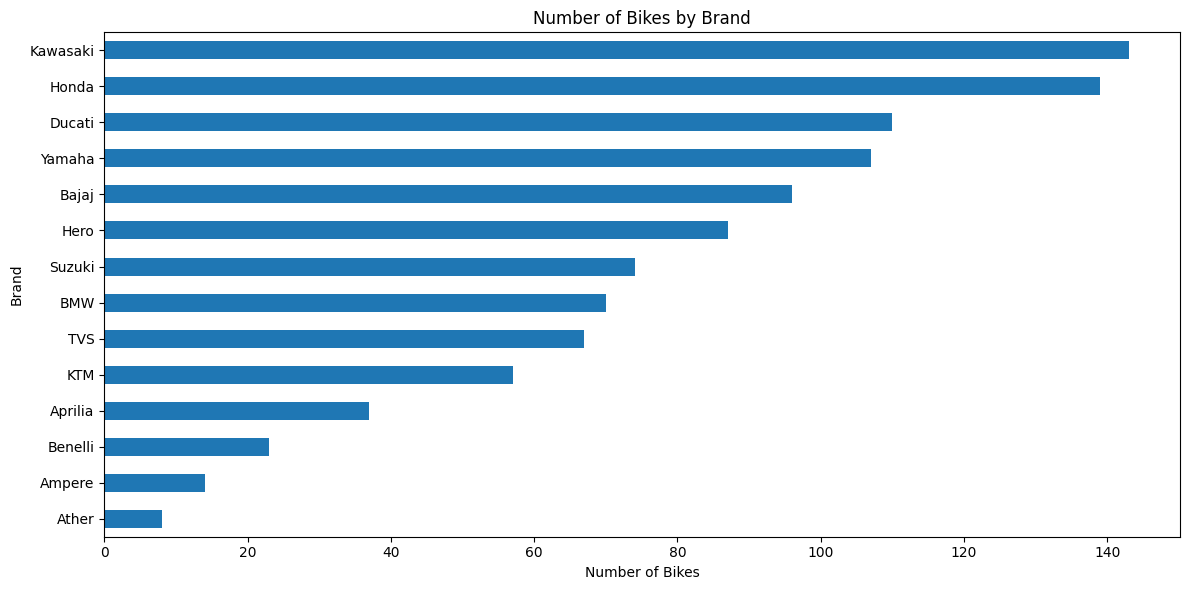

In [16]:
plt.figure(figsize=(12, 6))

brand_counts.sort_values().plot(
    kind="barh"
)

plt.title("Number of Bikes by Brand")
plt.xlabel("Number of Bikes")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

This is Univariate Analysis because we are analyzing one variable: Brand

# Data Quality Assessment

Droping unwanted columns

In [17]:
df.drop(columns = ["URL"],inplace = True)

In [18]:
df.head()

,Bike_Name,Brand,Price,Mileage,Engine_Capacity,Transmission,Kerb_Weight,Fuel_Tank_Capacity,User_Rating,Fuel_Type
0,TVS Apache RTR 160,TVS,110695.0,61.0,159.70,5 Speed Manual,137.0,12.0,4.5,Petrol
1,TVS Apache RTR 180 [2018-2019],TVS,110695.0,46.0,177.00,5 Speed Manual,139.0,16.0,4.6,Petrol
2,TVS Apache RTR 180,TVS,127722.0,42.0,177.40,5 Speed Manual,140.0,12.0,4.6,Petrol
3,TVS Apache RTR 200 4V,TVS,138353.0,41.9,197.75,5 Speed Manual,152.0,12.0,4.5,Petrol
4,TVS Apache [2006],TVS,110695.0,18.0,NaN,NaN,NaN,NaN,4.5,NaN


In [19]:
# Missing Values
missing = df.isnull().sum()

print(missing)

Bike_Name               0
Brand                   0
Price                   0
Mileage                74
Engine_Capacity       201
Transmission          150
Kerb_Weight           239
Fuel_Tank_Capacity    247
User_Rating           300
Fuel_Type             192
dtype: int64


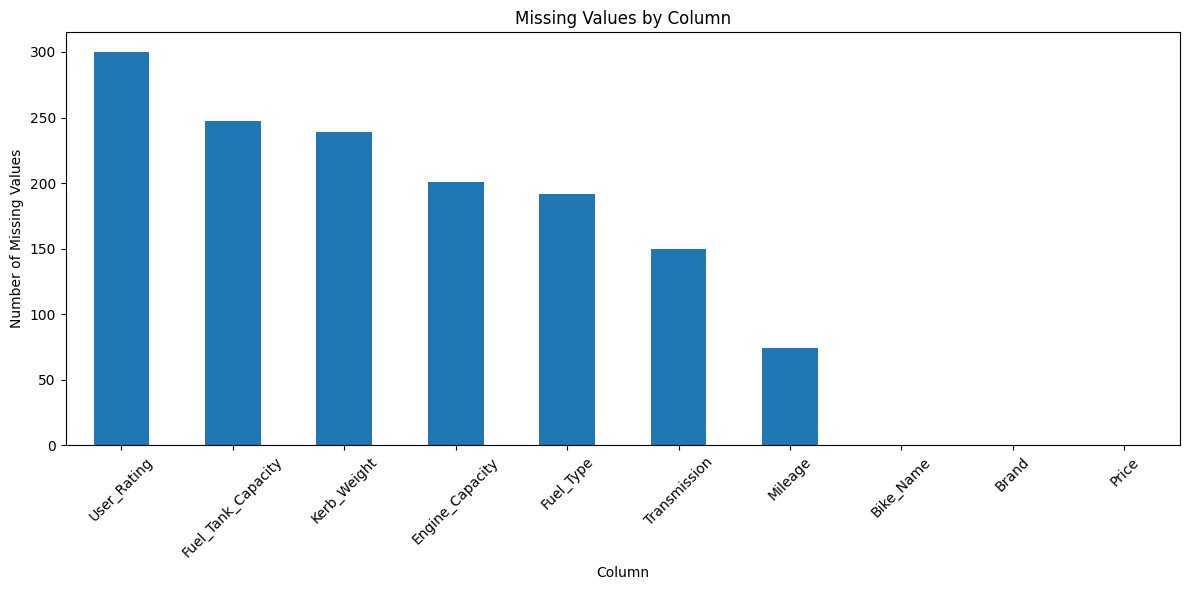

In [20]:
# Visualization
missing_plot = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

missing_plot.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [21]:
# Chcecking Duplicates
duplicate_count = df.duplicated().sum()

print("Duplicate Rows:", duplicate_count)

Duplicate Rows: 0


Handling Duplicates through column ["Bike_Name"]

In [22]:
df["Bike_Name"].duplicated().sum()

np.int64(0)

Handling Missing Values

In [23]:
df.isnull().sum()

,0
Bike_Name,0
Brand,0
Price,0
Mileage,74
Engine_Capacity,201
Transmission,150
Kerb_Weight,239
Fuel_Tank_Capacity,247
User_Rating,300
Fuel_Type,192


## Numeric Summary

In [24]:
numeric_columns = [
    "Price",
    "Mileage",
    "Engine_Capacity",
    "Kerb_Weight",
    "Fuel_Tank_Capacity",
    "User_Rating"
]

df[numeric_columns].describe()

,Price,Mileage,Engine_Capacity,Kerb_Weight,Fuel_Tank_Capacity,User_Rating
count,1.032000e+03,958.000000,831.000000,793.000000,785.000000,732.000000
mean,8.207845e+05,35.850772,541.337148,172.712484,13.777580,4.282787
std,1.079146e+06,18.203940,428.487583,54.787327,4.936377,0.944480
min,1.350000e+04,10.000000,49.000000,45.000000,2.300000,1.000000
25%,1.163330e+05,19.600000,149.690000,127.000000,11.000000,4.300000
50%,3.170000e+05,33.000000,373.000000,172.000000,14.000000,4.500000
75%,1.248948e+06,49.000000,937.000000,209.000000,17.000000,4.800000
max,1.000000e+07,150.000000,1833.000000,390.000000,33.000000,5.000000


The price distribution is highly spread out, because your dataset contains both affordable commuter bikes and very expensive premium/super-premium bikes.

In [25]:
# Separate Petrol Bikes
petrol_df = df[
    df["Fuel_Type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("petrol")
].copy()

print("Petrol Bike Records:", len(petrol_df))


Petrol Bike Records: 802


In [26]:
# Data Cleaning
cleaned_df = petrol_df.copy()

In [27]:
# Clean text columns
text_columns = [
    "Bike_Name",
    "Brand",
    "Transmission",
    "Fuel_Type"
]

for col in text_columns:

    cleaned_df[col] = (
        cleaned_df[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

In [28]:
# Clean Price
cleaned_df["Price"] = (
    cleaned_df["Price"]
    .astype(str)
    .str.replace(r"[₹,\s]", "", regex=True)
)

cleaned_df["Price"] = pd.to_numeric(
    cleaned_df["Price"],
    errors="coerce"
)

In [29]:
# Checking the price column
print(cleaned_df["Price"].dtype)
print(cleaned_df["Price"].isnull().sum())

float64
0


In [30]:
# Clean Mileage
cleaned_df["Mileage"] = (
    cleaned_df["Mileage"]
    .astype(str)
    .str.extract(r"([\d.]+)", expand=False)
)

cleaned_df["Mileage"] = pd.to_numeric(
    cleaned_df["Mileage"],
    errors="coerce"
)

In [31]:
# Clean Engine Capacity
cleaned_df["Engine_Capacity"] = (
    cleaned_df["Engine_Capacity"]
    .astype(str)
    .str.extract(r"([\d.]+)", expand=False)
)

cleaned_df["Engine_Capacity"] = pd.to_numeric(
    cleaned_df["Engine_Capacity"],
    errors="coerce"
)

In [32]:
#Clean Kerb Weight
cleaned_df["Kerb_Weight"] = (
    cleaned_df["Kerb_Weight"]
    .astype(str)
    .str.extract(r"([\d.]+)", expand=False)
)

cleaned_df["Kerb_Weight"] = pd.to_numeric(
    cleaned_df["Kerb_Weight"],
    errors="coerce"
)

In [33]:
# Clean Fuel Tank Capacity
cleaned_df["Fuel_Tank_Capacity"] = (
    cleaned_df["Fuel_Tank_Capacity"]
    .astype(str)
    .str.extract(r"([\d.]+)", expand=False)
)

cleaned_df["Fuel_Tank_Capacity"] = pd.to_numeric(
    cleaned_df["Fuel_Tank_Capacity"],
    errors="coerce"
)

In [34]:
# Clean User Rating
cleaned_df["User_Rating"] = (
    cleaned_df["User_Rating"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)", expand=False)
)

cleaned_df["User_Rating"] = pd.to_numeric(
    cleaned_df["User_Rating"],
    errors="coerce"
)

Handling Missing Values

In [35]:
#converting Nan Transmission - Unknown
cleaned_df["Transmission"] = (
    cleaned_df["Transmission"]
    .fillna("Unknown")
)

In [36]:
# Validate Data
print("Missing Values After Cleaning")
print(cleaned_df.isnull().sum())

Missing Values After Cleaning
Bike_Name               0
Brand                   0
Price                   0
Mileage                16
Engine_Capacity         2
Transmission            0
Kerb_Weight            45
Fuel_Tank_Capacity     33
User_Rating           181
Fuel_Type               0
dtype: int64


In [37]:
print("Duplicate Rows:",
      cleaned_df.duplicated().sum())

Duplicate Rows: 0


Removing/Filling Null Values

In [38]:
# Remove rows containing null values in any column

print("Before removing null values:", cleaned_df.shape)

cleaned_df = cleaned_df.dropna().reset_index(drop=True)

print("After removing null values:", cleaned_df.shape)

print("\nMissing Values After Removal:")
print(cleaned_df.isnull().sum())

Before removing null values: (802, 10)
After removing null values: (612, 10)

Missing Values After Removal:
Bike_Name             0
Brand                 0
Price                 0
Mileage               0
Engine_Capacity       0
Transmission          0
Kerb_Weight           0
Fuel_Tank_Capacity    0
User_Rating           0
Fuel_Type             0
dtype: int64


In [39]:
# Check whether any null values remain

print("Total null values:", cleaned_df.isnull().sum().sum())

print("Total duplicate rows:", cleaned_df.duplicated().sum())

Total null values: 0
Total duplicate rows: 0


In [40]:
cleaned_df

,Bike_Name,Brand,Price,Mileage,Engine_Capacity,Transmission,Kerb_Weight,Fuel_Tank_Capacity,User_Rating,Fuel_Type
0,TVS Apache RTR 160,TVS,110695.0,61.00,159.70,5 Speed Manual,137.0,12.0,4.5,Petrol
1,TVS Apache RTR 180 [2018-2019],TVS,110695.0,46.00,177.00,5 Speed Manual,139.0,16.0,4.6,Petrol
2,TVS Apache RTR 180,TVS,127722.0,42.00,177.40,5 Speed Manual,140.0,12.0,4.6,Petrol
3,TVS Apache RTR 200 4V,TVS,138353.0,41.90,197.75,5 Speed Manual,152.0,12.0,4.5,Petrol
4,TVS Apache RR 310 [2020-2023],TVS,110695.0,30.00,312.20,6 Speed Manual,169.0,11.0,4.7,Petrol
...,...,...,...,...,...,...,...,...,...,...
607,Ducati Streetfighter V4 [2019-2023],Ducati,2925963.0,13.15,1103.00,6 Speed Manual,201.0,16.0,4.9,Petrol
608,Ducati Streetfighter V4 [2024],Ducati,2925963.0,13.15,1103.00,6 Speed Manual,201.0,16.0,4.8,Petrol
609,Ducati SuperSport [2018-2019],Ducati,1716100.0,19.00,937.00,6 Speed Manual,210.0,16.0,4.6,Petrol
610,Ducati SuperSport,Ducati,1716100.0,17.80,937.00,6 Speed Manual,210.0,16.0,4.8,Petrol


Saving the cleaned Data

In [41]:
cleaned_df.to_csv('cleaned_bike_data.csv', index=False)

In [42]:
# Data quality report

quality_report = pd.DataFrame({
    "Data_Type": cleaned_df.dtypes.astype(str),
    "Unique_Values": cleaned_df.nunique(),
    "Missing_Values": cleaned_df.isnull().sum(),
    "Missing_Percentage": (
        cleaned_df.isnull().mean() * 100
    ).round(2)
})

display(quality_report)

,Data_Type,Unique_Values,Missing_Values,Missing_Percentage
Bike_Name,string,612,0,0.0
Brand,string,12,0,0.0
Price,float64,215,0,0.0
Mileage,float64,126,0,0.0
Engine_Capacity,float64,175,0,0.0
Transmission,string,8,0,0.0
Kerb_Weight,float64,181,0,0.0
Fuel_Tank_Capacity,float64,86,0,0.0
User_Rating,float64,20,0,0.0
Fuel_Type,string,1,0,0.0


Numerical Summary

In [43]:
# Select numerical columns

numeric_columns = [
    "Price",
    "Mileage",
    "Engine_Capacity",
    "Kerb_Weight",
    "Fuel_Tank_Capacity",
    "User_Rating"
]

# Statistical summary
display(cleaned_df[numeric_columns].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Price,612.0,709982.08,1107194.91,13500.0,93491.0,195200.00,790500.0,10000000.0
Mileage,612.0,37.25,18.64,10.0,20.0,35.00,50.0,150.0
Engine_Capacity,612.0,478.63,409.00,49.9,148.0,293.52,848.5,1833.0
Kerb_Weight,612.0,169.47,50.00,45.0,129.0,167.00,204.0,390.0
Fuel_Tank_Capacity,612.0,13.34,4.70,2.3,11.0,13.50,16.5,33.0
User_Rating,612.0,4.30,0.97,1.0,4.3,4.60,4.8,5.0


In [44]:
# Additional statistical measures

numeric_summary = pd.DataFrame({
    "Mean": cleaned_df[numeric_columns].mean(),
    "Median": cleaned_df[numeric_columns].median(),
    "Mode": cleaned_df[numeric_columns].mode().iloc[0],
    "Standard_Deviation": cleaned_df[numeric_columns].std(),
    "Skewness": cleaned_df[numeric_columns].skew()
}).round(2)

display(numeric_summary)

,Mean,Median,Mode,Standard_Deviation,Skewness
Price,709982.08,195200.00,79537.0,1107194.91,3.21
Mileage,37.25,35.00,18.0,18.64,0.91
Engine_Capacity,478.63,293.52,649.0,409.00,0.93
Kerb_Weight,169.47,167.00,112.0,50.00,0.71
Fuel_Tank_Capacity,13.34,13.50,17.0,4.70,0.17
User_Rating,4.30,4.60,4.6,0.97,-2.78


Compare mean and median to identify potentially skewed distributions. A mean much larger than the median often indicates a right-skewed variable, such as price.

# Feature engineering

In [45]:
# Price Category

cleaned_df["Price_Category"] = pd.cut(
    cleaned_df["Price"],
    bins=[0, 100000, 200000, 500000, float("inf")],
    labels=["Budget", "Mid-Range", "Premium", "Luxury"],
    right=False
)

display(cleaned_df["Price_Category"].value_counts())

,count
Price_Category,
Luxury,190
Budget,168
Mid-Range,152
Premium,102


In [46]:
# Engine Category

cleaned_df["Engine_Category"] = pd.cut(
    cleaned_df["Engine_Capacity"],
    bins=[0, 125, 200, 400, float("inf")],
    labels=["Entry", "Commuter", "Mid-Range", "High-Performance"],
    right=True
)

display(cleaned_df["Engine_Category"].value_counts())

,count
Engine_Category,
High-Performance,243
Entry,149
Mid-Range,115
Commuter,105


In [47]:
# Mileage Category

cleaned_df["Mileage_Category"] = pd.cut(
    cleaned_df["Mileage"],
    bins=[0, 40, 50, 60, float("inf")],
    labels=["Low", "Moderate", "Good", "Excellent"],
    right=False
)

display(cleaned_df["Mileage_Category"].value_counts())

,count
Mileage_Category,
Low,355
Moderate,96
Excellent,93
Good,68


In [48]:
# Price per CC
cleaned_df["Price_per_CC"] = (
    cleaned_df["Price"] / cleaned_df["Engine_Capacity"]
).round(2)

# Mileage relative to price
cleaned_df["Mileage_per_Lakh"] = (
    cleaned_df["Mileage"] / (cleaned_df["Price"] / 100000)
).round(2)

display(
    cleaned_df[
        [
            "Bike_Name",
            "Price",
            "Price_Category",
            "Engine_Capacity",
            "Engine_Category",
            "Mileage",
            "Mileage_Category",
            "Price_per_CC",
            "Mileage_per_Lakh"
        ]
    ].head(10)
)

,Bike_Name,Price,Price_Category,Engine_Capacity,Engine_Category,Mileage,Mileage_Category,Price_per_CC,Mileage_per_Lakh
0,TVS Apache RTR 160,110695.0,Mid-Range,159.70,Commuter,61.0,Excellent,693.14,55.11
1,TVS Apache RTR 180 [2018-2019],110695.0,Mid-Range,177.00,Commuter,46.0,Moderate,625.40,41.56
2,TVS Apache RTR 180,127722.0,Mid-Range,177.40,Commuter,42.0,Moderate,719.97,32.88
3,TVS Apache RTR 200 4V,138353.0,Mid-Range,197.75,Commuter,41.9,Moderate,699.64,30.28
4,TVS Apache RR 310 [2020-2023],110695.0,Mid-Range,312.20,Mid-Range,30.0,Low,354.56,27.10
5,TVS Apache RR 310,262268.0,Premium,312.20,Mid-Range,34.7,Low,840.06,13.23
6,TVS Apache RTR 160 4V,116479.0,Mid-Range,159.70,Commuter,41.4,Moderate,729.36,35.54
7,TVS Apache RTR 165RP,110695.0,Mid-Range,165.00,Commuter,45.0,Moderate,670.88,40.65
8,TVS Apache RTR 180 [2019],110695.0,Mid-Range,177.00,Commuter,42.0,Moderate,625.40,37.94
9,TVS Apache RTR 180 ABS [2019],110695.0,Mid-Range,177.00,Commuter,40.0,Moderate,625.40,36.14


# Univariate analysis

What to analyze: Are most bikes concentrated in affordable price ranges, or are expensive models influencing the distribution?

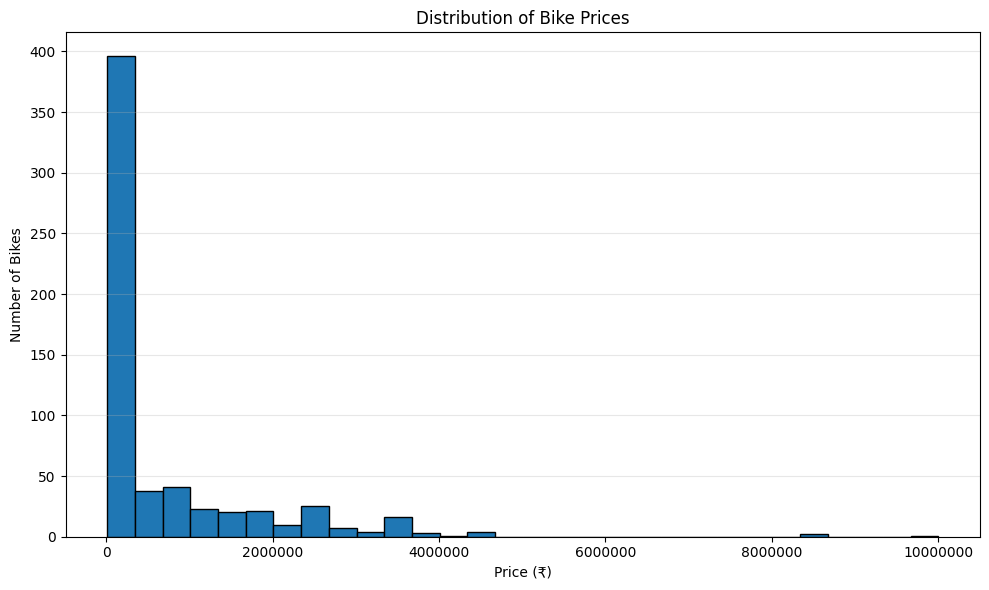

In [49]:
# Price distribution
plt.figure(figsize=(10, 6))

plt.hist(cleaned_df["Price"], bins=30, edgecolor="black")

plt.title("Distribution of Bike Prices")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Bikes")
plt.ticklabel_format(style="plain", axis="x")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

What to analyze: Which engine-capacity ranges are most common among the retained bikes?

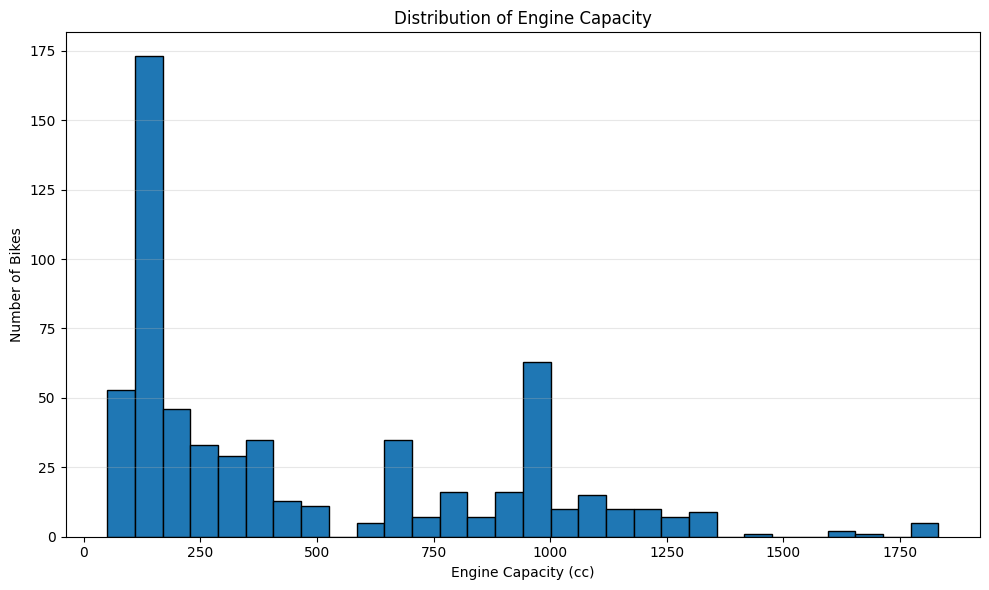

In [50]:
# Engine capacity distribution
plt.figure(figsize=(10, 6))

plt.hist(
    cleaned_df["Engine_Capacity"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Engine Capacity")
plt.xlabel("Engine Capacity (cc)")
plt.ylabel("Number of Bikes")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

What to analyze: Which brands have the highest representation in your scraped sample? This reflects the sample, not necessarily actual market share.

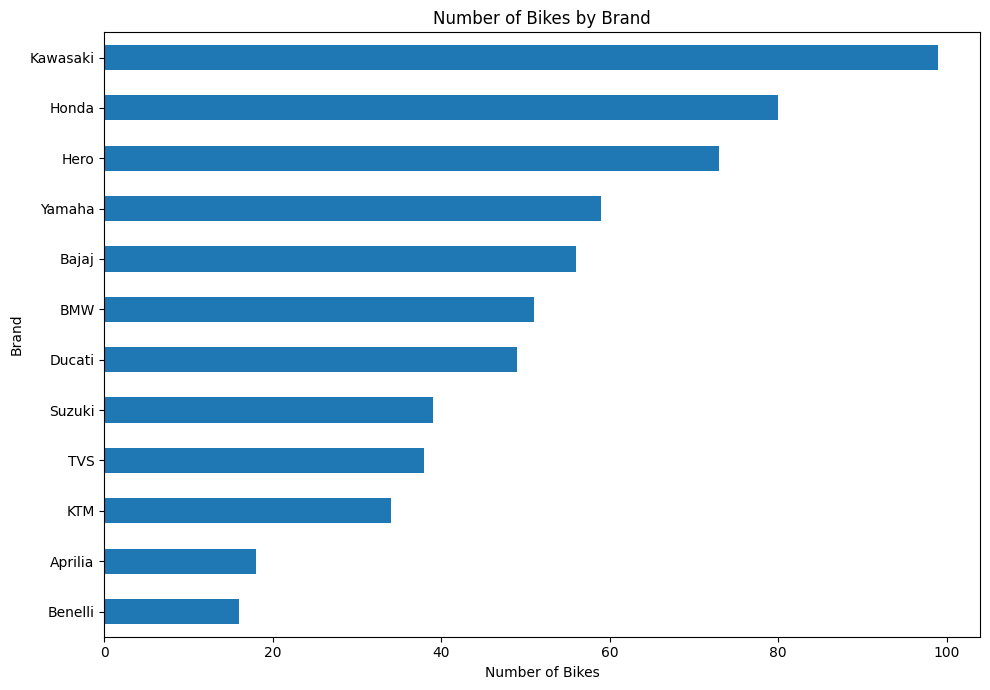

,count
Brand,
Kawasaki,99
Honda,80
Hero,73
Yamaha,59
Bajaj,56
BMW,51
Ducati,49
Suzuki,39
TVS,38


In [51]:
# Number of bikes by brand
brand_counts = cleaned_df["Brand"].value_counts().sort_values()

plt.figure(figsize=(10, 7))

brand_counts.plot(kind="barh")

plt.title("Number of Bikes by Brand")
plt.xlabel("Number of Bikes")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

display(brand_counts.sort_values(ascending=False))

# Bivariate analysis

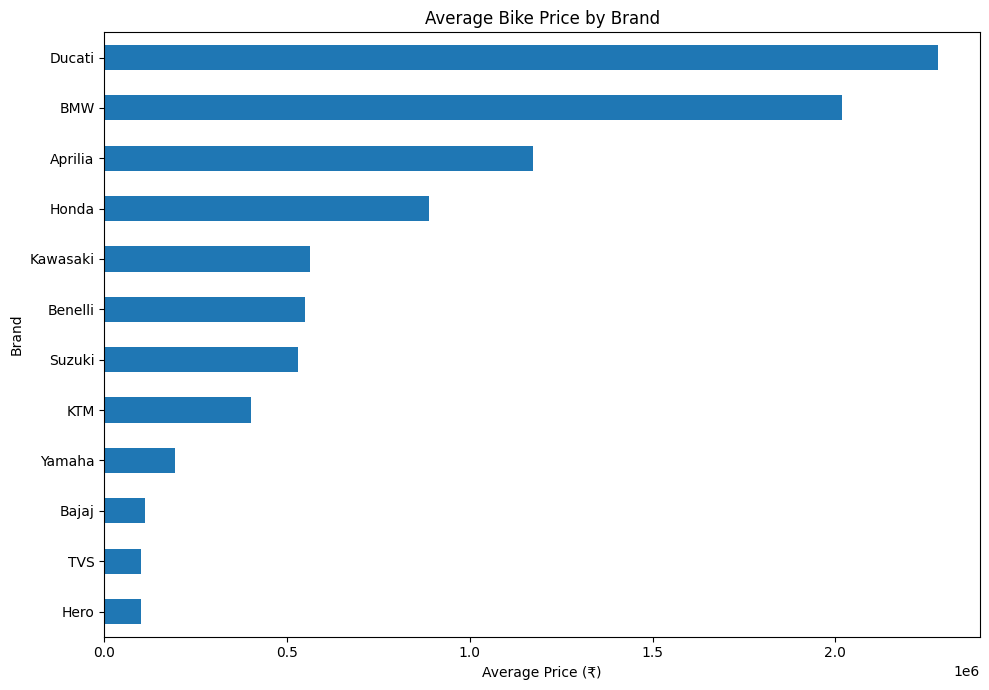

,Price
Brand,
Ducati,2282052.90
BMW,2019594.51
Aprilia,1172891.78
Honda,889458.28
Kawasaki,561809.90
Benelli,550048.00
Suzuki,529326.41
KTM,401558.62
Yamaha,192031.58


In [52]:
# Average price by brand
brand_avg_price = (
    cleaned_df.groupby("Brand")["Price"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 7))

brand_avg_price.plot(kind="barh")

plt.title("Average Bike Price by Brand")
plt.xlabel("Average Price (₹)")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

display(brand_avg_price.sort_values(ascending=False).round(2))

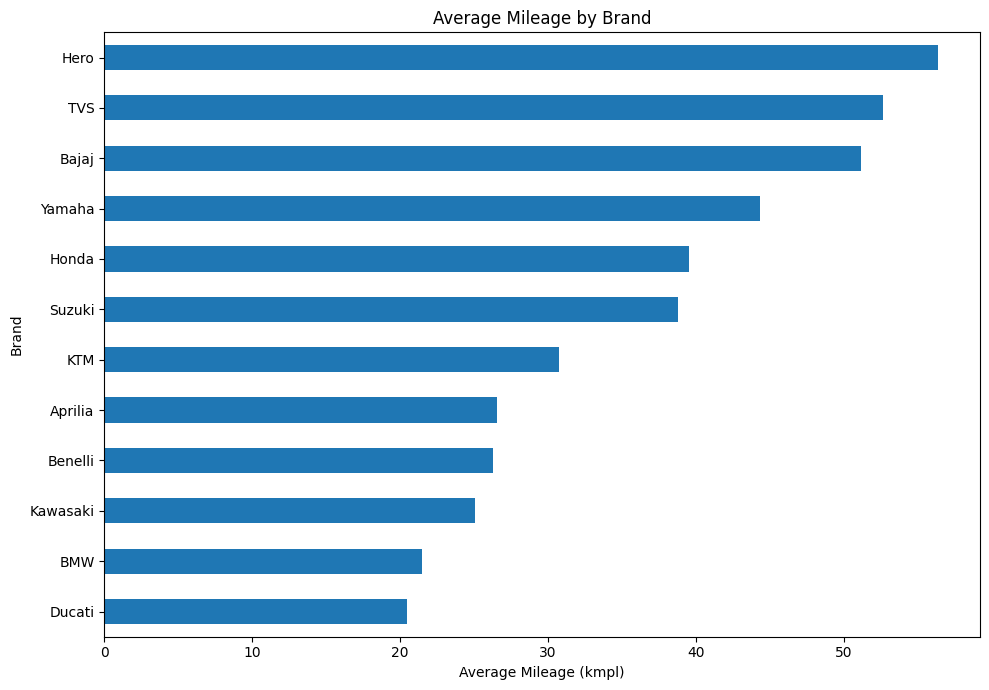

,Mileage
Brand,
Hero,56.39
TVS,52.66
Bajaj,51.14
Yamaha,44.31
Honda,39.55
Suzuki,38.79
KTM,30.74
Aprilia,26.54
Benelli,26.25


In [53]:
# Average mileage by brand
brand_avg_mileage = (
    cleaned_df.groupby("Brand")["Mileage"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 7))

brand_avg_mileage.plot(kind="barh")

plt.title("Average Mileage by Brand")
plt.xlabel("Average Mileage (kmpl)")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

display(brand_avg_mileage.sort_values(ascending=False).round(2))

,Bike_Name,Brand,Price
590,Ducati Panigale V4 Lamborghini,Ducati,10000000.0
591,Ducati Panigale V4 R [2018-2019],Ducati,8499000.0
592,Ducati Panigale V4 R,Ducati,8499000.0
94,Honda Gold Wing GL1800 [2016-2017],Honda,4430000.0
95,Honda Goldwing [2020-2021],Honda,4430000.0
106,Honda Old Generation Goldwing Tour 2023,Honda,4430000.0
584,Ducati Multistrada V4 RS,Ducati,4346700.0
170,Yamaha Vmax,Yamaha,4250000.0
495,BMW K 1600 B [2018-2019],BMW,3800000.0
496,BMW K1300 R,BMW,3800000.0


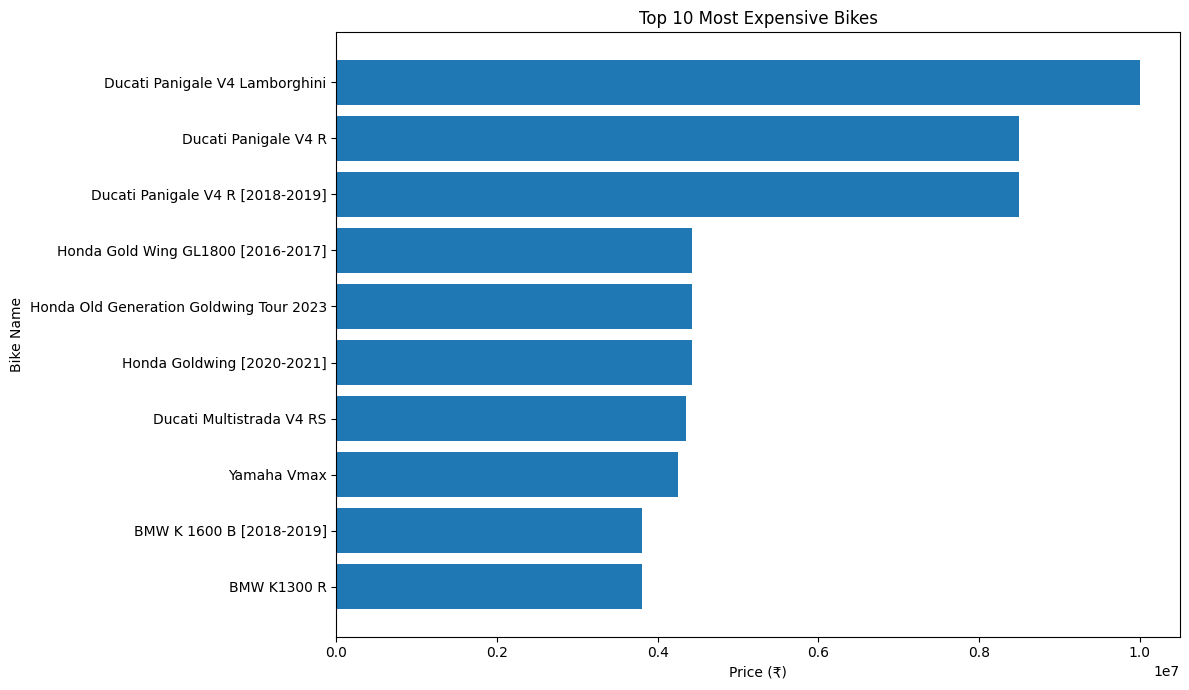

In [54]:
# Top 10 expensive bikes
top_10_expensive = cleaned_df.nlargest(
    10, "Price"
)[["Bike_Name", "Brand", "Price"]]

display(top_10_expensive)

plot_df = top_10_expensive.sort_values("Price")

plt.figure(figsize=(12, 7))

plt.barh(plot_df["Bike_Name"], plot_df["Price"])

plt.title("Top 10 Most Expensive Bikes")
plt.xlabel("Price (₹)")
plt.ylabel("Bike Name")

plt.tight_layout()
plt.show()

In [55]:
# Top 10 highest-rated bikes
top_10_rated = cleaned_df.nlargest(
    10, "User_Rating"
)[["Bike_Name", "Brand", "User_Rating", "Price"]]

display(top_10_rated)

,Bike_Name,Brand,User_Rating,Price
47,Honda Africa Twin [2019-2020],Honda,5.0,1279000.0
70,Honda CB650R [2018-2023],Honda,5.0,195200.0
114,Honda Transalp XL750 [2024],Honda,5.0,1320000.0
142,Yamaha MT-09 [2016-2017],Yamaha,5.0,166586.0
176,Yamaha YZF R1 [2012],Yamaha,5.0,175693.0
317,KTM 390 Adventure R,KTM,5.0,387903.0
355,Suzuki GSX-8R [2024],Suzuki,5.0,991236.0
385,Kawasaki KLX230RS [2023-2025],Kawasaki,5.0,481026.0
389,Kawasaki KX450,Kawasaki,5.0,991958.0
413,Kawasaki Ninja H2 SX [2018-2019],Kawasaki,5.0,317000.0


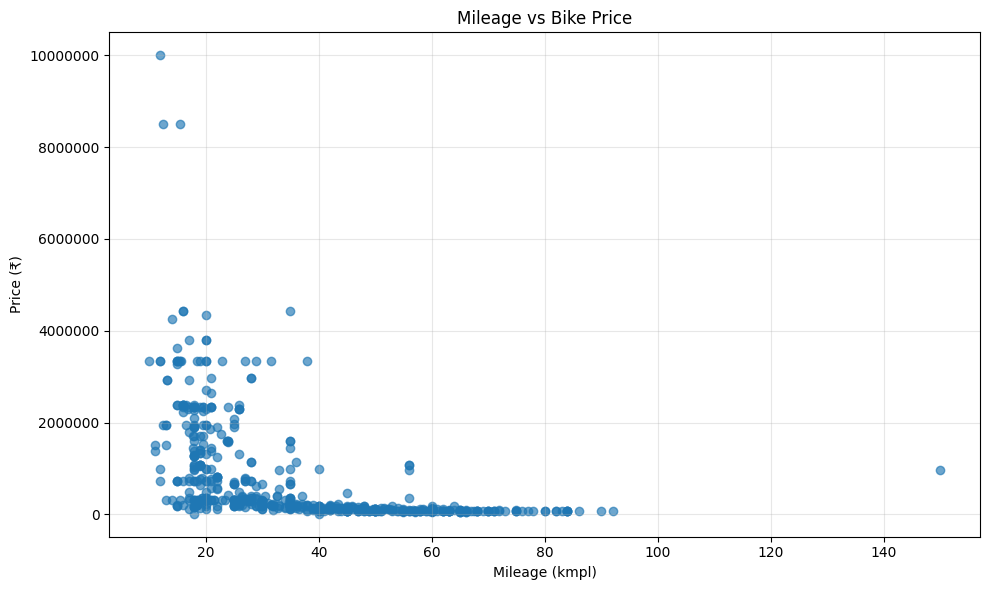

Mileage vs Price correlation: -0.499


In [56]:
# Mileage vs Price
plt.figure(figsize=(10, 6))

plt.scatter(
    cleaned_df["Mileage"],
    cleaned_df["Price"],
    alpha=0.65
)

plt.title("Mileage vs Bike Price")
plt.xlabel("Mileage (kmpl)")
plt.ylabel("Price (₹)")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Mileage vs Price correlation:",
    round(cleaned_df["Mileage"].corr(cleaned_df["Price"]), 3)
)

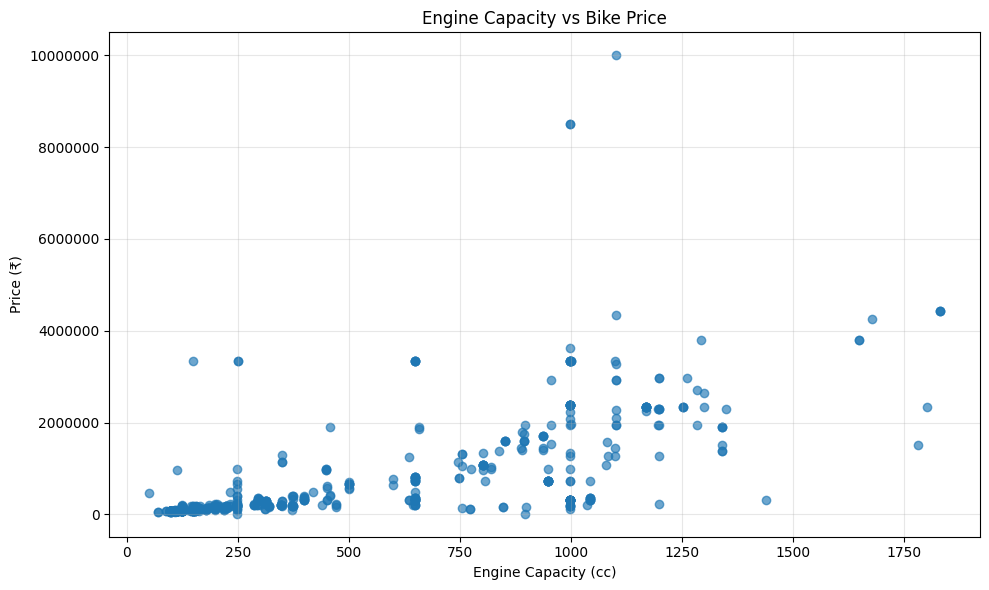

Engine Capacity vs Price correlation: 0.685


In [57]:
# Engine capacity vs price
plt.figure(figsize=(10, 6))

plt.scatter(
    cleaned_df["Engine_Capacity"],
    cleaned_df["Price"],
    alpha=0.65
)

plt.title("Engine Capacity vs Bike Price")
plt.xlabel("Engine Capacity (cc)")
plt.ylabel("Price (₹)")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Engine Capacity vs Price correlation:",
    round(
        cleaned_df["Engine_Capacity"].corr(cleaned_df["Price"]),
        3
    )
)

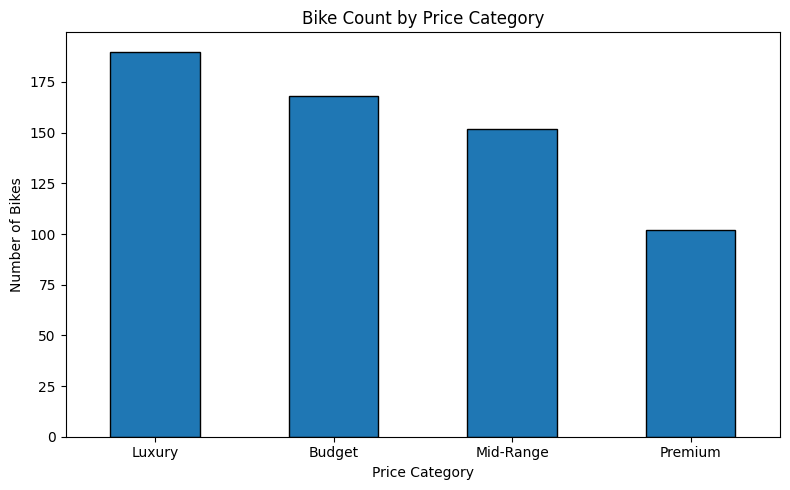

In [58]:
# Price Category Distribution
price_counts = cleaned_df["Price_Category"].value_counts()

plt.figure(figsize=(8, 5))

price_counts.plot(kind="bar", edgecolor="black")

plt.title("Bike Count by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Bikes")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

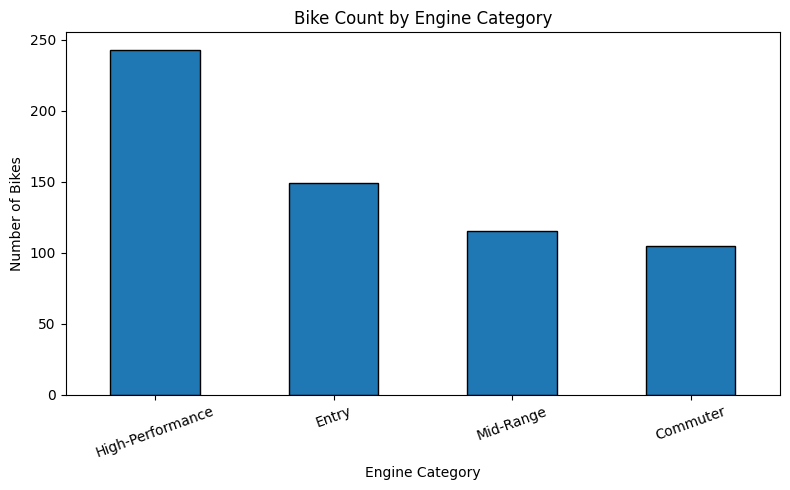

In [59]:
# Engine category distribution
engine_counts = cleaned_df["Engine_Category"].value_counts()

plt.figure(figsize=(8, 5))

engine_counts.plot(kind="bar", edgecolor="black")

plt.title("Bike Count by Engine Category")
plt.xlabel("Engine Category")
plt.ylabel("Number of Bikes")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

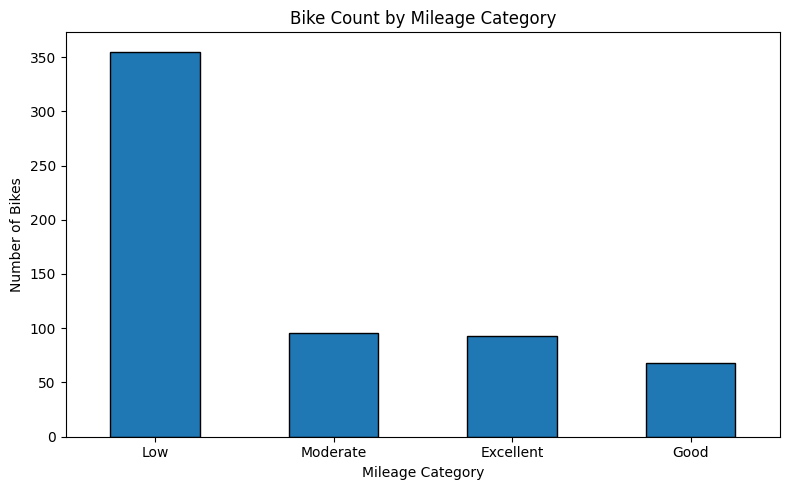

In [60]:
# Mileage category distribution
mileage_counts = cleaned_df["Mileage_Category"].value_counts()

plt.figure(figsize=(8, 5))

mileage_counts.plot(kind="bar", edgecolor="black")

plt.title("Bike Count by Mileage Category")
plt.xlabel("Mileage Category")
plt.ylabel("Number of Bikes")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Multivariate analysis

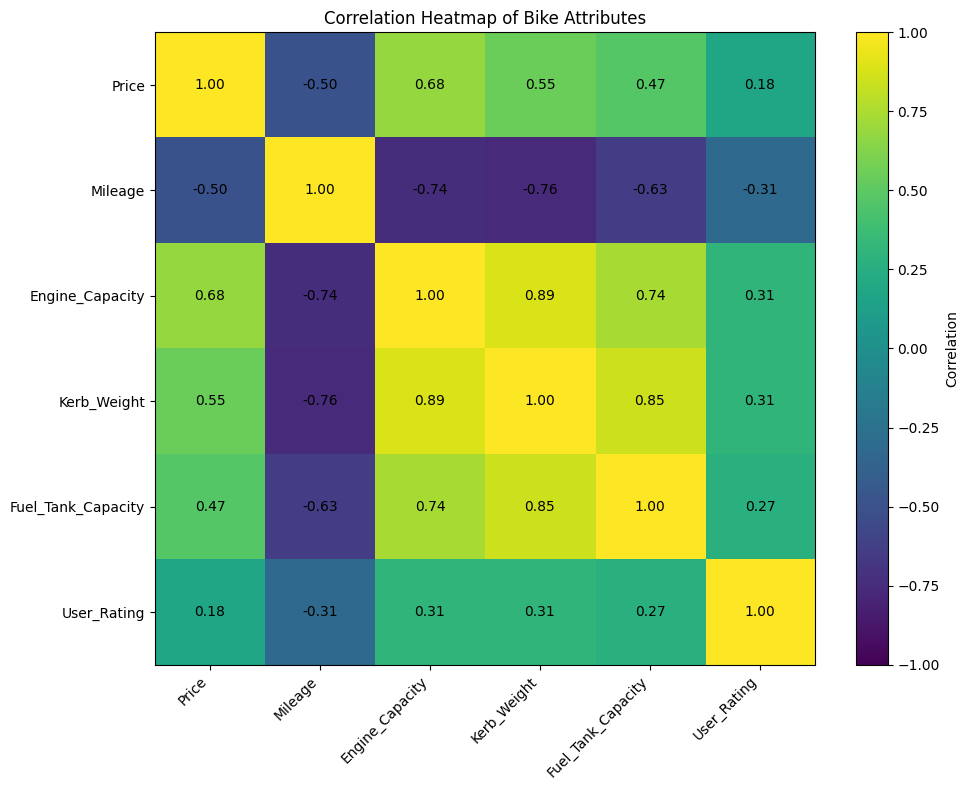

,Price,Mileage,Engine_Capacity,Kerb_Weight,Fuel_Tank_Capacity,User_Rating
Price,1.000,-0.499,0.685,0.553,0.469,0.179
Mileage,-0.499,1.000,-0.739,-0.758,-0.634,-0.314
Engine_Capacity,0.685,-0.739,1.000,0.886,0.739,0.309
Kerb_Weight,0.553,-0.758,0.886,1.000,0.851,0.312
Fuel_Tank_Capacity,0.469,-0.634,0.739,0.851,1.000,0.271
User_Rating,0.179,-0.314,0.309,0.312,0.271,1.000


In [61]:
# Correlation heatmap
corr = cleaned_df[
    [
        "Price",
        "Mileage",
        "Engine_Capacity",
        "Kerb_Weight",
        "Fuel_Tank_Capacity",
        "User_Rating"
    ]
].corr()

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")

ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

fig.colorbar(image, ax=ax, label="Correlation")

ax.set_title("Correlation Heatmap of Bike Attributes")

plt.tight_layout()
plt.show()

display(corr.round(3))

Interpretation: This chart helps identify numerical variables that move together. For example, a positive engine-capacity/price correlation would indicate that higher-engine-capacity bikes tend to be more expensive in this dataset.

In [62]:
# Q1: Which brands have the highest average prices?

display(
    cleaned_df.groupby("Brand")
    .agg(
        Average_Price=("Price", "mean"),
        Bike_Count=("Bike_Name", "count")
    )
    .sort_values("Average_Price", ascending=False)
    .round(2)
)

,Average_Price,Bike_Count
Brand,,
Ducati,2282052.90,49
BMW,2019594.51,51
Aprilia,1172891.78,18
Honda,889458.28,80
Kawasaki,561809.90,99
Benelli,550048.00,16
Suzuki,529326.41,39
KTM,401558.62,34
Yamaha,192031.58,59


In [63]:
# Q2: Which brands have the highest average mileage?

display(
    cleaned_df.groupby("Brand")
    .agg(
        Average_Mileage=("Mileage", "mean"),
        Bike_Count=("Bike_Name", "count")
    )
    .sort_values("Average_Mileage", ascending=False)
    .round(2)
)

,Average_Mileage,Bike_Count
Brand,,
Hero,56.39,73
TVS,52.66,38
Bajaj,51.14,56
Yamaha,44.31,59
Honda,39.55,80
Suzuki,38.79,39
KTM,30.74,34
Aprilia,26.54,18
Benelli,26.25,16


In [64]:
# Q3: What are the 10 most expensive bikes?

display(
    cleaned_df.nlargest(10, "Price")[
        ["Bike_Name", "Brand", "Price"]
    ]
)

,Bike_Name,Brand,Price
590,Ducati Panigale V4 Lamborghini,Ducati,10000000.0
591,Ducati Panigale V4 R [2018-2019],Ducati,8499000.0
592,Ducati Panigale V4 R,Ducati,8499000.0
94,Honda Gold Wing GL1800 [2016-2017],Honda,4430000.0
95,Honda Goldwing [2020-2021],Honda,4430000.0
106,Honda Old Generation Goldwing Tour 2023,Honda,4430000.0
584,Ducati Multistrada V4 RS,Ducati,4346700.0
170,Yamaha Vmax,Yamaha,4250000.0
495,BMW K 1600 B [2018-2019],BMW,3800000.0
496,BMW K1300 R,BMW,3800000.0


In [65]:
# Q4: Which bikes have the highest user ratings?

display(
    cleaned_df.nlargest(10, "User_Rating")[
        ["Bike_Name", "Brand", "User_Rating"]
    ]
)

,Bike_Name,Brand,User_Rating
47,Honda Africa Twin [2019-2020],Honda,5.0
70,Honda CB650R [2018-2023],Honda,5.0
114,Honda Transalp XL750 [2024],Honda,5.0
142,Yamaha MT-09 [2016-2017],Yamaha,5.0
176,Yamaha YZF R1 [2012],Yamaha,5.0
317,KTM 390 Adventure R,KTM,5.0
355,Suzuki GSX-8R [2024],Suzuki,5.0
385,Kawasaki KLX230RS [2023-2025],Kawasaki,5.0
389,Kawasaki KX450,Kawasaki,5.0
413,Kawasaki Ninja H2 SX [2018-2019],Kawasaki,5.0


In [66]:
# Q5: What is the correlation between engine capacity and price?

print(
    round(
        cleaned_df["Engine_Capacity"].corr(cleaned_df["Price"]),
        3
    )
)

0.685


In [67]:
# Q6: What is the correlation between mileage and price?

print(
    round(
        cleaned_df["Mileage"].corr(cleaned_df["Price"]),
        3
    )
)

-0.499


In [68]:
# Q7: Which brands have the lowest average prices?

display(
    cleaned_df.groupby("Brand")
    .agg(
        Average_Price=("Price", "mean"),
        Bike_Count=("Bike_Name", "count")
    )
    .sort_values("Average_Price")
    .round(2)
)

,Average_Price,Bike_Count
Brand,,
Hero,99874.67,73
TVS,100935.11,38
Bajaj,111562.32,56
Yamaha,192031.58,59
KTM,401558.62,34
Suzuki,529326.41,39
Benelli,550048.00,16
Kawasaki,561809.90,99
Honda,889458.28,80


In [69]:
# Q8: What is the most common engine category?

display(
    cleaned_df["Engine_Category"]
    .value_counts()
    .rename_axis("Engine_Category")
    .reset_index(name="Bike_Count")
)

,Engine_Category,Bike_Count
0,High-Performance,243
1,Entry,149
2,Mid-Range,115
3,Commuter,105


In [70]:
# Q9: What is the most common price category?

display(
    cleaned_df["Price_Category"]
    .value_counts()
    .rename_axis("Price_Category")
    .reset_index(name="Bike_Count")
)

,Price_Category,Bike_Count
0,Luxury,190
1,Budget,168
2,Mid-Range,152
3,Premium,102


In [71]:
# Q10: Which bikes have the highest mileage relative to price?

display(
    cleaned_df.nlargest(10, "Mileage_per_Lakh")[
        [
            "Bike_Name",
            "Brand",
            "Price",
            "Mileage",
            "Mileage_per_Lakh"
        ]
    ]
)

,Bike_Name,Brand,Price,Mileage,Mileage_per_Lakh
127,Yamaha Fazer 25,Yamaha,13500.0,40.0,296.30
538,Aprilia Shiver 900,Aprilia,13500.0,18.0,133.33
28,TVS Sport,TVS,65729.0,80.0,121.71
34,TVS XL 100 Heavy Duty,TVS,47922.0,57.0,118.94
282,Hero Splendor iSmart,Hero,77751.0,92.0,118.33
284,Hero Splendor PRO,Hero,77751.0,90.0,115.75
204,Bajaj Platina 110 [2018-2020],Bajaj,71049.0,80.0,112.60
93,Honda CD 110 Dream,Honda,58726.0,65.0,110.68
253,Hero HF Deluxe Eco,Hero,58726.0,65.0,110.68
255,Hero HF Deluxe,Hero,58726.0,65.0,110.68


# Brand performance summary

In [72]:
brand_summary = (
    cleaned_df.groupby("Brand")
    .agg(
        Bike_Count=("Bike_Name", "count"),
        Average_Price=("Price", "mean"),
        Median_Price=("Price", "median"),
        Average_Mileage=("Mileage", "mean"),
        Average_Engine_CC=("Engine_Capacity", "mean"),
        Average_Rating=("User_Rating", "mean")
    )
    .round(2)
    .sort_values("Average_Price", ascending=False)
)

display(brand_summary)



,Bike_Count,Average_Price,Median_Price,Average_Mileage,Average_Engine_CC,Average_Rating
Brand,,,,,,
Ducati,49,2282052.90,1870300.0,20.46,998.26,4.65
BMW,51,2019594.51,2349945.0,21.45,955.75,4.58
Aprilia,18,1172891.78,419814.5,26.54,569.98,4.29
Honda,80,889458.28,195200.0,39.55,428.27,4.20
Kawasaki,99,561809.90,349020.0,25.08,698.34,4.66
Benelli,16,550048.00,650986.5,26.25,432.53,4.46
Suzuki,39,529326.41,190771.0,38.79,505.38,4.36
KTM,34,401558.62,269590.5,30.74,338.76,4.62
Yamaha,59,192031.58,116333.0,44.31,291.53,4.32


# Generate insights from actual results

In [73]:
# Data-driven observations

highest_price_brand = brand_summary["Average_Price"].idxmax()
lowest_price_brand = brand_summary["Average_Price"].idxmin()

highest_mileage_brand = brand_summary["Average_Mileage"].idxmax()

most_common_price_category = (
    cleaned_df["Price_Category"].value_counts().idxmax()
)

most_common_engine_category = (
    cleaned_df["Engine_Category"].value_counts().idxmax()
)

most_expensive_bike = cleaned_df.loc[cleaned_df["Price"].idxmax()]
highest_rated_bike = cleaned_df.loc[cleaned_df["User_Rating"].idxmax()]

engine_price_corr = cleaned_df["Engine_Capacity"].corr(cleaned_df["Price"])
mileage_price_corr = cleaned_df["Mileage"].corr(cleaned_df["Price"])

print("1. Highest average-price brand:", highest_price_brand)
print("2. Lowest average-price brand:", lowest_price_brand)
print("3. Highest average-mileage brand:", highest_mileage_brand)
print("4. Most common price category:", most_common_price_category)
print("5. Most common engine category:", most_common_engine_category)
print("6. Most expensive bike:", most_expensive_bike["Bike_Name"])
print("   Price:", most_expensive_bike["Price"])
print("7. Highest-rated bike:", highest_rated_bike["Bike_Name"])
print("   Rating:", highest_rated_bike["User_Rating"])
print("8. Engine-price correlation:", round(engine_price_corr, 3))
print("   Mileage-price correlation:", round(mileage_price_corr, 3))

1. Highest average-price brand: Ducati
2. Lowest average-price brand: Hero
3. Highest average-mileage brand: Hero
4. Most common price category: Luxury
5. Most common engine category: High-Performance
6. Most expensive bike: Ducati Panigale V4 Lamborghini
   Price: 10000000.0
7. Highest-rated bike: Honda Africa Twin [2019-2020]
   Rating: 5.0
8. Engine-price correlation: 0.685
   Mileage-price correlation: -0.499


## Business Insights
- The collected sample includes motorcycles across budget, mid-range, premium, and luxury price categories.
- The large number of records in the Luxury category indicates that high-priced models are well represented in this particular dataset.
- Ducati and BMW have the highest average listed prices among the brands in the cleaned sample.
- Hero, TVS, and Bajaj have higher brand-level average mileage values than the other brands represented.
- The positive engine-capacity/price correlation suggests that higher engine capacity tends to occur alongside higher listed prices in this sample.
- The negative mileage/price correlation suggests that higher-priced records tend to be associated with lower mileage values in this sample; this relationship may also reflect differences in motorcycle segments.

## Business Recommendations
- For customers: Compare price, mileage, engine capacity, and ratings together rather than choosing a motorcycle using only one specification.
- For manufacturers: Review customer ratings and specification patterns to identify areas for product improvement.
- For marketing teams: Consider separate communication strategies for budget, mid-range, premium, and luxury motorcycle segments.
- For market researchers: Expand the dataset across more brands, models, and collection dates before drawing broader market conclusions.
- For analysts: Use interactive filters and brand-level comparisons to make the collected information easier to explore.

## Challenges and Limitations
### Challenges
- Website HTML structures and page content may vary between models.
- Some specifications are not available on every motorcycle page.
- Extracted values may contain symbols, units, commas, or inconsistent text formats.
- Missing values reduce the number of records available for complete-case analysis.
- Website content can change, so the same scraping code may require maintenance.
### Limitations
- The dataset is a collected sample, not a complete census of the motorcycle market.
- The analysis is limited to petrol motorcycles.
- Removing incomplete rows may introduce selection bias if missingness is not random.
- Listed prices and specifications may change over time and may vary by location.
- User ratings are only those available in the collected records and may not represent all owners.
- The analysis is descriptive and does not establish causal relationships.

## Future Scope
1. Scheduled data collection: Run the scraper periodically to monitor changes in listed prices and specifications.
2. Broader source coverage: Collect comparable data from additional motorcycle websites, subject to their terms and access rules.
3. Price prediction: Explore regression models to estimate listed prices using features such as engine capacity, mileage, weight, and brand.
4. Recommendation system: Build a tool that filters and recommends motorcycles based on a user's budget and preferred specifications.
5. Interactive dashboard: Develop a Streamlit, Power BI, or Tableau dashboard with brand, price, mileage, and engine filters.
6. Electric motorcycle comparison: Extend the dataset to include electric two-wheelers and compare relevant specifications.
7. Data quality improvements: Track missingness, validate extracted values, and preserve collection timestamps and source URLs for auditability.

## Conclusion
This project demonstrates an end-to-end workflow for collecting website data and analyzing it with Python. BikeWale motorcycle information was extracted and organized into a structured dataset, followed by data cleaning, feature engineering, exploratory analysis, and visualization.

The final cleaned dataset contains 612 complete petrol motorcycle records. The analysis highlights differences in brand representation, listed prices, mileage, engine categories, and customer ratings within the collected sample. It also identifies relationships between engine capacity, mileage, and price.

The project provides practical experience in web scraping and data analytics. It can be extended through scheduled data collection, predictive modeling, recommendation systems, and interactive dashboards.